In [4]:
import pandas as pd
import os
path = "StudentPerformanceFactors.csv"
df=pd.read_csv("StudentPerformanceFactors.csv")
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [5]:
!pip install matplotlib scikit-learn numpy

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error
import numpy as np
print(df.columns.tolist())
print(df.shape)
print(df.head())

['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']
(6607, 20)
   Hours_Studied  Attendance Parental_Involvement Access_to_Resources  \
0             23          84                  Low                High   
1             19          64                  Low              Medium   
2             24          98               Medium              Medium   
3             29          89                  Low              Medium   
4             19          92               Medium              Medium   

  Extracurricular_Activities  Sleep_Hours  Previous_Scores Motivation_Level  \
0                         No            7               73              Low   


In [7]:
x_simple=df[["Hours_Studied"]]
x_multiple=df[["Hours_Studied","Attendance","Sleep_Hours"]]
y=df["Exam_Score"]
print(x_simple.head())

   Hours_Studied
0             23
1             19
2             24
3             29
4             19


In [8]:
x_train_s, x_test_s, y_train, y_test = train_test_split(
    x_simple, y, test_size=0.2, random_state=42
)

x_train_m, x_test_m, _, _ = train_test_split(
    x_multiple, y, test_size=0.2, random_state=42
)

print("Training data:", x_train_s.shape)
print("Testing data:", x_test_s.shape)

Training data: (5285, 1)
Testing data: (1322, 1)


In [9]:
simple_model = LinearRegression()

simple_model.fit(x_train_s, y_train)

simple_predictions = simple_model.predict(x_test_s)

print("\n--- Simple Linear Regression ---")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])
print("R2 Score:", r2_score(y_test, simple_predictions))
print("RMSE:", np.sqrt(
    mean_squared_error(y_test, simple_predictions)
))


--- Simple Linear Regression ---
Intercept: 61.51116746904424
Coefficient: 0.285668744443087
R2 Score: 0.2319868674542106
RMSE: 3.294832513010839


In [10]:
multiple_model = LinearRegression()

multiple_model.fit(x_train_m, y_train)

multiple_predictions = multiple_model.predict(x_test_m)

print("\n--- Multiple Linear Regression ---")
print("Intercept:", multiple_model.intercept_)
print("Coefficients:", multiple_model.coef_)

print("R2 Score:", r2_score(y_test, multiple_predictions))

print("RMSE:", np.sqrt(
    mean_squared_error(y_test, multiple_predictions)
))


--- Multiple Linear Regression ---
Intercept: 45.937048965691304
Coefficients: [ 0.2891957   0.19827206 -0.04740738]
R2 Score: 0.5884110279740732
RMSE: 2.412019889780555


In [11]:
new_student_simple = pd.DataFrame({
    "Hours_Studied": [6]
})

new_student_multiple = pd.DataFrame({
    "Hours_Studied": [6],
    "Attendance": [80],
    "Sleep_Hours": [7]
})

print("\nPredicted Exam Score using Simple Regression:",
      simple_model.predict(new_student_simple)[0])

print("Predicted Exam Score using Multiple Regression:",
      multiple_model.predict(new_student_multiple)[0])


Predicted Exam Score using Simple Regression: 63.22517993570276
Predicted Exam Score using Multiple Regression: 63.202136544225105


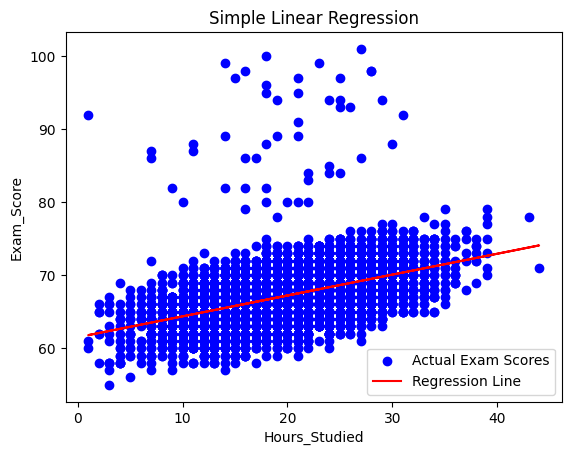

In [12]:
plt.scatter(
    df["Hours_Studied"],
    df["Exam_Score"],
    color="blue",
    label="Actual Exam Scores"
)

plt.plot(
    df["Hours_Studied"],
    simple_model.predict(x_simple),
    color="red",
    label="Regression Line"
)

plt.xlabel("Hours_Studied")
plt.ylabel("Exam_Score")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()